# SVM Regression

In [24]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import accuracy_score, classification_report, r2_score
from sklearn import datasets
import matplotlib.pyplot as plt

In [25]:
# Using Diabetes dataset for regression
df = datasets.load_diabetes(as_frame=True).frame
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [26]:
df.size

4862

In [27]:
df.shape

(442, 11)

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [29]:
df.isnull().sum()

age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

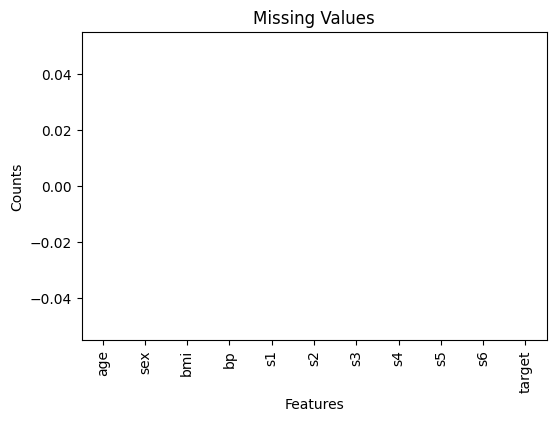

In [30]:
df.isnull().sum().plot(kind="bar", title="Missing Values", xlabel="Features", ylabel="Counts", figsize=(6,4))
plt.show()

In [31]:
# Splitting the dataset
X = df.drop("target", axis=1)
y = df["target"]

In [32]:
X.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [33]:
y.head()

0    151.0
1     75.0
2    141.0
3    206.0
4    135.0
Name: target, dtype: float64

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.3, 
    random_state=42, 
)

In [35]:
y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1)).ravel() # Scale in 2D
y_test_scaled = y_scaler.transform(y_test.values.reshape(-1, 1)).ravel()

In [36]:
y_train_scaled

array([ 6.89917243e-01,  1.36584298e+00,  3.20071083e-01,  1.32758304e+00,
        1.37859630e+00, -1.31235335e+00,  1.05976340e+00, -1.05728703e+00,
       -1.90061552e-01,  1.45511620e+00, -1.08279366e+00,  2.08002867e+00,
        1.21280319e+00,  1.23818601e-03,  4.85864189e-01, -4.83387817e-01,
       -9.29753873e-01, -4.06867922e-01,  1.34033635e+00,  4.73110873e-01,
        1.76119578e+00, -1.26134009e+00, -5.98167660e-01,  7.15423875e-01,
       -8.02220714e-01,  1.26381646e+00, -8.78740609e-01,  1.25106314e+00,
       -1.21032682e+00, -9.68013820e-01,  5.87890716e-01, -9.68013820e-01,
        1.16178993e+00,  2.69057819e-01, -1.42713319e+00, -3.43101343e-01,
       -1.28684672e+00, -7.63960766e-01, -6.36427608e-01,  5.75137400e-01,
        1.41685625e+00,  1.62090930e+00,  1.20004988e+00,  1.31482972e+00,
        7.79190454e-01,  1.90148225e+00,  2.05291240e-01, -1.21032682e+00,
        1.56989604e+00,  7.02670559e-01, -2.02814868e-01,  5.62384084e-01,
       -3.81361290e-01, -

In [37]:
# By default rbf kernel is used.

# Model Buiding
model = SVR()
model.fit(X_train, y_train_scaled)


,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,1.0
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


In [38]:
y_test_pred_scaled = model.predict(X_test)
y_train_pred_scaled = model.predict(X_train)

In [39]:
# For training 
print("train r2: ", r2_score(y_train_scaled, y_train_pred_scaled))
print("test r2: ", r2_score(y_test_scaled, y_test_pred_scaled))


train r2:  0.6596361676267712
test r2:  0.48844443151651906


In [40]:
y_pred_scaled = model.predict(X_test)
# Don't need to to turn it back to original scale, as r2 score is scale invariant
print("r2: ", r2_score(y_test_scaled, y_pred_scaled))

r2:  0.48844443151651906


In [41]:
# Using Linear Kernel

model = SVR(kernel="linear")
model.fit(X_train, y_train_scaled)
# y_pred_scaled = model.predict(X_test)

y_test_pred_scaled = model.predict(X_test)
y_train_pred_scaled = model.predict(X_train)

print("train r2: ", r2_score(y_train_scaled, y_train_pred_scaled))
print("test r2: ", r2_score(y_test_scaled, y_test_pred_scaled))


train r2:  0.45191229982475245
test r2:  0.4433761323833776


In [42]:
# 2: Polynomial Kernel

model = SVR(kernel="poly")
model.fit(X_train, y_train_scaled)
# y_pred_scaled = model.predict(X_test)

y_test_pred_scaled = model.predict(X_test)
y_train_pred_scaled = model.predict(X_train)

print("train r2: ", r2_score(y_train_scaled, y_train_pred_scaled))
print("test r2: ", r2_score(y_test_scaled, y_test_pred_scaled))


train r2:  0.5790920834310542
test r2:  0.24203771038107735


In [43]:
# 3: Sigmoid Kernel

model = SVR(kernel="sigmoid")
model.fit(X_train, y_train_scaled)
# y_pred_scaled = model.predict(X_test)

y_test_pred_scaled = model.predict(X_test)
y_train_pred_scaled = model.predict(X_train)

print("train r2: ", r2_score(y_train_scaled, y_train_pred_scaled))
print("test r2: ", r2_score(y_test_scaled, y_test_pred_scaled))

train r2:  -19.72119344073131
test r2:  -15.316808189576822


In [44]:
# Hyperparameter Tuning using GridSearchCV

from sklearn.model_selection import GridSearchCV

In [45]:
param_grid = {
    "C": [1, 2, 10, 15, 25, 25, 50, 70, 80, 90, 100],
    "kernel": ["linear", "poly", "sigmoid", "rbf"],
    "epsilon": [0.01, 0.1, 0.3, 0.5, 0.7, 0.8]
}

In [46]:
svr = SVR()

grid_search = GridSearchCV(svr, param_grid, scoring="r2", cv=5)

grid_search.fit(X_train, y_train_scaled)

,estimator,SVR()
,param_grid,"{'C': [1, 2, ...], 'epsilon': [0.01, 0.1, ...], 'kernel': ['linear', 'poly', ...]}"
,scoring,'r2'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,kernel,'linear'


In [47]:
print("Best Parameters: ", grid_search.best_params_)

Best Parameters:  {'C': 15, 'epsilon': 0.1, 'kernel': 'linear'}


In [ ]:
best_model = SVR(kernel="linear", C=15, epsilon=0.1)

best_model.fit(X_train, y_train_scaled)

# y_pred_scaled = model.predict(X_test)

y_test_pred_scaled = best_model.predict(X_test)
y_train_pred_scaled = best_model.predict(X_train)

print("train r2: ", r2_score(y_train_scaled, y_train_pred_scaled))
print("test r2: ", r2_score(y_test_scaled, y_test_pred_scaled))

train r2:  0.5159940317635723
test r2:  0.46995146194571336
